# Setup

## GPU Initialization

In [1]:
import os
os.environ.setdefault("KMP_DUPLICATE_LIB_OK", "TRUE")            # before torch/numpy
os.environ.setdefault("HF_HUB_DISABLE_SYMLINKS_WARNING", "1")

# Keras 3 runs the CNN / BiLSTM on the PyTorch backend (no TensorFlow).
# MUST be set before `import keras` anywhere in the kernel.
os.environ.setdefault("KERAS_BACKEND", "torch")
os.environ.setdefault("USE_TF", "0")                            # stop transformers importing TF

import sys, subprocess, importlib.util

# torch: needs the cu130 wheel for the RTX 5070 (Blackwell / sm_120)
try:
    import torch
    assert torch.cuda.is_available() and torch.version.cuda
    print(f"OK: torch {torch.__version__} (CUDA {torch.version.cuda})")
except (ImportError, AssertionError):
    subprocess.check_call([sys.executable, "-m", "pip", "install", "--upgrade",
        "torch", "torchvision", "--index-url", "https://download.pytorch.org/whl/cu130"])
    raise SystemExit(">>> Installed torch — RESTART KERNEL, then re-run from top <<<")

# accelerate: required by HF Trainer. Install only if missing, never -U.
if importlib.util.find_spec("accelerate") is None:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "accelerate>=1.1.0"])
    raise SystemExit(">>> Installed accelerate — RESTART KERNEL <<<")

# keras 3: pure-Python, uses the torch already installed. No TensorFlow.
if importlib.util.find_spec("keras") is None:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "keras>=3.5"])
    raise SystemExit(">>> Installed keras — RESTART KERNEL <<<")

OK: torch 2.13.0+cu130 (CUDA 13.0)


In [2]:
import gc, torch

torch.backends.cuda.matmul.allow_tf32 = True
torch.backends.cudnn.allow_tf32 = True

assert torch.cuda.is_available(), "CUDA not available — check Cell 1, restart kernel."
device = torch.device("cuda")

p = torch.cuda.get_device_properties(0)
print(f"{torch.__version__} | {p.name} | {p.total_memory/1e9:.1f} GB "
      f"| cap {p.major}.{p.minor} | bf16={torch.cuda.is_bf16_supported()}")

def free_gpu():
    """del the trainer/model in the notebook first, then call this."""
    gc.collect(); torch.cuda.empty_cache(); torch.cuda.reset_peak_memory_stats()
    print(f"GPU allocated: {torch.cuda.memory_allocated()/1e9:.2f} GB")

2.13.0+cu130 | NVIDIA GeForce RTX 5070 Laptop GPU | 8.5 GB | cap 12.0 | bf16=True


In [3]:
import keras

print("PyTorch:", torch.__version__)
print("Keras:", keras.__version__, "| backend:", keras.config.backend())
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

# Keras uses the same CUDA device as torch. Quick proof it lands on the GPU:
_probe = keras.layers.Dense(1)
_probe.build((None, 4))
print("Keras variable device:", _probe.weights[0].value.device)

PyTorch: 2.13.0+cu130
Keras: 3.15.1 | backend: torch
CUDA available: True
GPU: NVIDIA GeForce RTX 5070 Laptop GPU
Keras variable device: cuda:0


## Imports

In [4]:
import os
import gc
import json
import random
import re
import pickle
import joblib
import copy
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

import torch

from sklearn.model_selection import (
    train_test_split,
    GroupShuffleSplit
)

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)

from scipy.sparse import hstack

from datasets import Dataset

from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    DataCollatorWithPadding,
    TrainingArguments,
    Trainer
)

# --- Keras 3 on the PyTorch backend (KERAS_BACKEND set in the GPU-init cell) ---
import keras
from keras import Sequential
from keras.layers import (
    Embedding,
    Conv1D,
    GlobalMaxPooling1D,
    Bidirectional,
    LSTM,
    Dense,
    Dropout
)

assert keras.config.backend() == "torch", (
    f"Keras backend is {keras.config.backend()!r}, expected 'torch'. "
    "Set os.environ['KERAS_BACKEND']='torch' before importing keras and restart the kernel."
)

## Paths & Variables

In [5]:
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
keras.utils.set_random_seed(SEED)   # seeds python / numpy / torch for the keras backend

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# ============================================================
# PATHS
# ============================================================

OUTPUT_PATH = "models"   # relative to the notebook; "/models" would write to the drive root

os.makedirs(OUTPUT_PATH, exist_ok=True)

# ============================================================
# MODEL OUTPUT LAYOUT
# models/<category>/{logreg.joblib, textcnn/, bilstm/, distilbert/}
# ============================================================

CATEGORY_NAME = "cyberbullying"

CATEGORY_DIR = f"{OUTPUT_PATH}/{CATEGORY_NAME}"
TEXTCNN_DIR = f"{CATEGORY_DIR}/textcnn"
BILSTM_DIR = f"{CATEGORY_DIR}/bilstm"
DISTILBERT_DIR = f"{CATEGORY_DIR}/distilbert"

for _dir in (CATEGORY_DIR, TEXTCNN_DIR, BILSTM_DIR, DISTILBERT_DIR):
    os.makedirs(_dir, exist_ok=True)

# ============================================================
# TRAINING FILES
# ============================================================

CYBER_PATH = "train/cyberbullying_tweets.csv"

# ============================================================
# FINAL TEST FILES
# DO NOT USE DURING MODEL DEVELOPMENT
# ============================================================


# ============================================================
# TRANSFORMER SETTINGS
# ============================================================

DISTILBERT_NAME = "distilbert-base-uncased"

MAX_LENGTH = 128

TRAIN_BATCH_SIZE = 16
EVAL_BATCH_SIZE = 32

NUM_EPOCHS = 3
LEARNING_RATE = 2e-5

# ============================================================
# NEURAL NETWORK SETTINGS
# ============================================================

VOCAB_SIZE = 30000
SEQUENCE_LENGTH = 128
EMBEDDING_DIM = 128

# ============================================================
# DATASET EXPERIMENT SETTINGS
# ============================================================


# ============================================================
# BAGGING
# Start small first.
#
# Later compare:
# 1, 3, 5, 10, 15
# ============================================================

N_BAGS = 3

# Data Preprocessing

## Load Datasets

In [6]:
cyber_raw = pd.read_csv(CYBER_PATH)

print("Cyberbullying:", cyber_raw.shape)
display(cyber_raw.head())

Cyberbullying: (47692, 2)


,tweet_text,cyberbullying_type
0,"In other words #katandandre, your food was cra...",not_cyberbullying
1,Why is #aussietv so white? #MKR #theblock #ImA...,not_cyberbullying
2,@XochitlSuckkks a classy whore? Or more red ve...,not_cyberbullying
3,"@Jason_Gio meh. :P thanks for the heads up, b...",not_cyberbullying
4,@RudhoeEnglish This is an ISIS account pretend...,not_cyberbullying


In [7]:
def clean_text_dataframe(df):
    df = df.copy()

    df["text"] = (
        df["text"]
        .fillna("")
        .astype(str)
        .str.strip()
    )

    df = df[df["text"] != ""]

    df = df.drop_duplicates(subset=["text"])

    return df.reset_index(drop=True)

## Prepare Cyber Dataset

In [8]:
CYBER_CLASSES = ["not_cyberbullying", "religion", "age", "gender", "ethnicity", "other_cyberbullying"]
CYBER_LABEL_MAP = {label:index for index, label in enumerate(CYBER_CLASSES)}

with open(f"{CATEGORY_DIR}/labels.json", "w") as f:
    json.dump(CYBER_CLASSES, f, indent=2)

def prepare_cyber(df):

    df = df.copy()

    df["text"] = (
        df["tweet_text"]
        .fillna("")
        .astype(str)
    )

    df = df[
        df["cyberbullying_type"].isin(CYBER_CLASSES)
    ]

    df["label"] = (
        df["cyberbullying_type"]
        .map(CYBER_LABEL_MAP)
        .astype(int)
    )

    df["source"] = "cyberbullying"

    return clean_text_dataframe(df[["text", "label", "source"]])

cyber = prepare_cyber(cyber_raw)

print(cyber.shape)
print(cyber["label"].value_counts().sort_index())
display(cyber.head())

(46017, 3)
label
0    7937
1    7995
2    7992
3    7898
4    7952
5    6243
Name: count, dtype: int64


,text,label,source
0,"In other words #katandandre, your food was cra...",0,cyberbullying
1,Why is #aussietv so white? #MKR #theblock #ImA...,0,cyberbullying
2,@XochitlSuckkks a classy whore? Or more red ve...,0,cyberbullying
3,"@Jason_Gio meh. :P thanks for the heads up, b...",0,cyberbullying
4,@RudhoeEnglish This is an ISIS account pretend...,0,cyberbullying


## Lock Train Test Split

In [9]:
cyber_train, cyber_temp = train_test_split(
    cyber,
    test_size=0.30,
    random_state=SEED,
    stratify=cyber["label"]
)

cyber_val, cyber_test = train_test_split(
    cyber_temp,
    test_size=0.50,
    random_state=SEED,
    stratify=cyber_temp["label"]
)

print("Cyber train:", cyber_train.shape)
print("Cyber validation:", cyber_val.shape)
print("Cyber test:", cyber_test.shape)

SPLIT_PATH = "train/cyber_splits"

os.makedirs(SPLIT_PATH, exist_ok=True)

cyber_train.to_csv(f"{SPLIT_PATH}/cyber_train.csv", index=False)
cyber_val.to_csv(f"{SPLIT_PATH}/cyber_validation.csv", index=False)
cyber_test.to_csv(f"{SPLIT_PATH}/cyber_test_LOCKED.csv",index=False)

print("LOCKED cyber test split saved.")

Cyber train: (32211, 3)
Cyber validation: (6903, 3)
Cyber test: (6903, 3)
LOCKED cyber test split saved.


# Base Model Support Functions

## Multiclass Evaluation Function

In [10]:
def evaluate_multiclass(y_true, probabilities, model_name):

    predictions = np.argmax(probabilities, axis=1)

    result = {
        "model": model_name,
        "accuracy": accuracy_score(y_true, predictions),
        # ====================================================
        # MACRO METRICS
        # Every class receives equal importance
        # ====================================================
        "precision_macro": precision_score(y_true, predictions, average="macro", zero_division=0),
        "recall_macro": recall_score(y_true, predictions, average="macro", zero_division=0),
        "f1_macro": f1_score(y_true, predictions, average="macro", zero_division=0),
        # ====================================================
        # WEIGHTED METRICS
        # Weighted according to class frequency
        # ====================================================
        "precision_weighted": precision_score(y_true, predictions, average="weighted", zero_division=0),
        "recall_weighted": recall_score(y_true, predictions, average="weighted", zero_division=0),
        "f1_weighted": f1_score(y_true, predictions, average="weighted", zero_division=0),
        # ====================================================
        # MULTICLASS ROC-AUC
        # One-vs-Rest
        # ====================================================
        "roc_auc_macro_ovr": roc_auc_score(y_true, probabilities, multi_class="ovr", average="macro")
    }

    print("\n" + "=" * 70)
    print(model_name)
    print("=" * 70)

    print(result)

    print("\nPer-class classification report:")
    print(classification_report(y_true, predictions, target_names=CYBER_CLASSES, zero_division=0))

    print("\nConfusion Matrix:")
    print(confusion_matrix(y_true,predictions))

    return result

## Text Vectorizer for Keras models

In [11]:
from inference import KerasTextVectorizer

print("KerasTextVectorizer ready (imported from inference.py).")

KerasTextVectorizer ready (imported from inference.py).


## Base Model Prediction Functions

In [12]:
def predict_cyber_lr(bundle, texts):

    X = hstack([
        bundle["word_vectorizer"].transform(texts),
        bundle["char_vectorizer"].transform(texts)
    ])

    return (bundle["model"].predict_proba(X))


def predict_cyber_neural(bundle, texts):

    # vectorize with the SAME adapted vocab used at training time
    X = bundle["vectorizer"](np.asarray(texts, dtype=object))

    return (bundle["model"].predict(X, batch_size=128, verbose=0))


def predict_cyber_distilbert(bundle, df):

    dataset = make_hf_dataset(df)
    output = (bundle["trainer"].predict(dataset))

    return torch.softmax(torch.tensor(output.predictions), dim=-1).numpy()

# Base Model Training Functions

## Model 1 - Multiclass Logistic Regression

In [13]:
def train_cyber_logistic(train_df, val_df, output_name):

    word_vectorizer = TfidfVectorizer(
        analyzer="word",
        ngram_range=(1, 2),
        min_df=2,
        max_features=50000,
        sublinear_tf=True
    )

    char_vectorizer = TfidfVectorizer(
        analyzer="char_wb",
        ngram_range=(3, 5),
        min_df=2,
        max_features=50000,
        sublinear_tf=True
    )

    X_train_word = (word_vectorizer.fit_transform(train_df["text"]))
    X_val_word = (word_vectorizer.transform(val_df["text"]))

    X_train_char = (char_vectorizer.fit_transform(train_df["text"]))
    X_val_char = (char_vectorizer.transform(val_df["text"]))

    X_train = hstack([X_train_word, X_train_char])
    X_val = hstack([X_val_word, X_val_char])

    model = LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        solver="lbfgs",
        random_state=SEED
    )
    model.fit(X_train, train_df["label"].values)

    probabilities = (model.predict_proba(X_val))

    predictions = np.argmax(probabilities, axis=1)

    print(
        classification_report(
            val_df["label"].values,
            predictions,
            target_names=CYBER_CLASSES,
            zero_division=0
        )
    )

    joblib.dump(
        {
            "model": model,
            "word_vectorizer": word_vectorizer,
            "char_vectorizer": char_vectorizer
        },
        f"{OUTPUT_PATH}/{output_name}.joblib"
    )

    return {
        "model": model,
        "word_vectorizer": word_vectorizer,
        "char_vectorizer": char_vectorizer,
        "probabilities": probabilities
    }

## Model 2 - TextCNN / CNN-1D 

In [14]:
def train_cyber_cnn(train_df, val_df, model_name, output_name, seed=42):

    keras.backend.clear_session()
    keras.utils.set_random_seed(seed)

    vectorizer = KerasTextVectorizer(
        max_tokens=VOCAB_SIZE,
        output_sequence_length=SEQUENCE_LENGTH
    )
    vectorizer.adapt(train_df["text"].values)

    X_train = vectorizer(train_df["text"].values)
    X_val = vectorizer(val_df["text"].values)
    y_train = train_df["label"].values
    y_val = val_df["label"].values

    model = Sequential([
        keras.Input(shape=(SEQUENCE_LENGTH,), dtype="int32"),
        Embedding(VOCAB_SIZE, EMBEDDING_DIM),
        Conv1D(128, kernel_size=5, activation="relu"),
        GlobalMaxPooling1D(),
        Dense(64, activation="relu"),
        Dropout(0.3),
        Dense(len(CYBER_CLASSES), activation="softmax",dtype="float32")
    ])

    model.compile(
        optimizer="adam",
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    checkpoint_path = f"{OUTPUT_PATH}/{output_name}.keras"

    model.fit(
        X_train, y_train,
        validation_data=(X_val, y_val),
        epochs=8,
        batch_size=64,
        callbacks=[
            keras.callbacks.EarlyStopping(
                monitor="val_loss",
                patience=2,
                restore_best_weights=True
            ),
            keras.callbacks.ModelCheckpoint(
                checkpoint_path,
                monitor="val_loss",
                save_best_only=True
            )
        ],
        verbose=1
    )

    probabilities = model.predict(X_val, batch_size=128, verbose=0)

    print(f"{model_name} -> saved best checkpoint to {checkpoint_path}")

    joblib.dump(vectorizer, f"{OUTPUT_PATH}/{output_name}_vectorizer.joblib")

    return {
        "model": model,
        "vectorizer": vectorizer,
        "probabilities": probabilities
    }

## Model 3 - BiLSTM

In [15]:
def train_cyber_bilstm(train_df, val_df, model_name, output_name, seed=42):

    # torch backend: LSTM has no fused cuDNN kernel -> GPU but slower than CNN
    keras.backend.clear_session()
    keras.utils.set_random_seed(seed)

    vectorizer = KerasTextVectorizer(
        max_tokens=VOCAB_SIZE,
        output_sequence_length=SEQUENCE_LENGTH
    )
    vectorizer.adapt(train_df["text"].values)

    X_train = vectorizer(train_df["text"].values)
    X_val = vectorizer(val_df["text"].values)
    y_train = train_df["label"].values
    y_val = val_df["label"].values

    model = Sequential([
        keras.Input(shape=(SEQUENCE_LENGTH,), dtype="int32"),
        Embedding(VOCAB_SIZE, EMBEDDING_DIM, mask_zero=True),
        Bidirectional(LSTM(64)),
        Dropout(0.3),
        Dense(64, activation="relu"),
        Dropout(0.3),
        Dense(len(CYBER_CLASSES), activation="softmax",dtype="float32")
    ])

    model.compile(
        optimizer="adam",
        loss=("sparse_categorical_crossentropy"),
        metrics=["accuracy"]
    )

    checkpoint_path = f"{OUTPUT_PATH}/{output_name}.keras"

    model.fit(
        X_train, y_train,
        validation_data=(X_val, y_val),
        epochs=8,
        batch_size=64,
        callbacks=[
            keras.callbacks.EarlyStopping(
                monitor="val_loss",
                patience=2,
                restore_best_weights=True
            ),
            keras.callbacks.ModelCheckpoint(
                checkpoint_path,
                monitor="val_loss",
                save_best_only=True
            )
        ],
        verbose=1
    )

    probabilities = model.predict(X_val, batch_size=128, verbose=0)

    print(f"{model_name} -> saved best checkpoint to {checkpoint_path}")

    joblib.dump(vectorizer, f"{OUTPUT_PATH}/{output_name}_vectorizer.joblib")

    return {
        "model": model,
        "vectorizer": vectorizer,
        "probabilities": probabilities
    }

## Model 4 - DistilBERT 

In [13]:
distil_tokenizer = (AutoTokenizer.from_pretrained(DISTILBERT_NAME))

data_collator = DataCollatorWithPadding(tokenizer=distil_tokenizer)

def tokenize_distilbert(batch):
    
    return distil_tokenizer(
        batch["text"],
        truncation=True,
        max_length=MAX_LENGTH
    )


def make_hf_dataset(df):
    dataset = Dataset.from_pandas(df[["text", "label"]], preserve_index=False)
    dataset = dataset.map(
        tokenize_distilbert,
        batched=True,
        remove_columns=["text"]
    )
    dataset = dataset.rename_column("label", "labels")
    
    return dataset

In [14]:
def cyber_metrics(eval_pred):

    logits, labels = eval_pred
    predictions = np.argmax(logits, axis=-1)

    return {
        "accuracy": accuracy_score(labels, predictions),
        "f1_macro": f1_score(labels, predictions, average="macro")
    }

In [18]:
def train_cyber_distilbert(train_df, val_df, output_name, seed=42):

    torch.manual_seed(seed)

    train_dataset = make_hf_dataset(train_df)
    val_dataset = make_hf_dataset(val_df)

    model = (AutoModelForSequenceClassification.from_pretrained(DISTILBERT_NAME, num_labels=len(CYBER_CLASSES)))

    args = TrainingArguments(
        output_dir=(f"{OUTPUT_PATH}/{output_name}"),
        num_train_epochs=NUM_EPOCHS,
        learning_rate=LEARNING_RATE,
        per_device_train_batch_size=16,
        per_device_eval_batch_size=32,
        eval_strategy="epoch",
        save_strategy="epoch",
        load_best_model_at_end=True,
        metric_for_best_model="f1_macro",
        greater_is_better=True,
        # RTX 5070 (Blackwell) -> bf16 is more stable than fp16
        bf16=torch.cuda.is_available(),
        save_total_limit=1,
        report_to="none",
        seed=seed
    )

    trainer = Trainer(
        model=model,
        args=args,
        train_dataset=train_dataset,
        eval_dataset=val_dataset,
        processing_class=distil_tokenizer,
        data_collator=data_collator,
        compute_metrics=cyber_metrics
    )

    trainer.train()

    results = trainer.evaluate()
    print(results)

    trainer.save_model(args.output_dir)
    distil_tokenizer.save_pretrained(args.output_dir)

    return {"trainer": trainer, "results": results, "path": args.output_dir}

# Base Model Training & Predictions

## Base Training

### Multi-class Logistic Regression Training

In [19]:
cyber_lr = train_cyber_logistic(
    cyber_train, 
    cyber_val, 
    output_name=f"{CATEGORY_NAME}/logreg"
)

                     precision    recall  f1-score   support

  not_cyberbullying       0.67      0.63      0.65      1191
           religion       0.97      0.95      0.96      1200
                age       0.97      0.97      0.97      1199
             gender       0.93      0.86      0.89      1184
          ethnicity       0.99      0.98      0.98      1193
other_cyberbullying       0.60      0.72      0.66       936

           accuracy                           0.86      6903
          macro avg       0.85      0.85      0.85      6903
       weighted avg       0.86      0.86      0.86      6903



### TextCNN Training

In [20]:
cyber_cnn = train_cyber_cnn(
    cyber_train,
    cyber_val,
    model_name="Cyberbullying TextCNN",
    output_name=f"{CATEGORY_NAME}/textcnn/textcnn_single"
)

W1011 12:50:59.321000 34564 site-packages\torch\utils\flop_counter.py:29] triton not found; flop counting will not work for triton kernels


Epoch 1/8
504/504 ━━━━━━━━━━━━━━━━━━━━ 7s 8ms/step - accuracy: 0.7709 - loss: 0.6030 - val_accuracy: 0.8518 - val_loss: 0.3627
Epoch 2/8
504/504 ━━━━━━━━━━━━━━━━━━━━ 4s 8ms/step - accuracy: 0.8951 - loss: 0.2773 - val_accuracy: 0.8544 - val_loss: 0.3630
Epoch 3/8
504/504 ━━━━━━━━━━━━━━━━━━━━ 4s 7ms/step - accuracy: 0.9509 - loss: 0.1412 - val_accuracy: 0.8514 - val_loss: 0.4273
Cyberbullying TextCNN -> saved best checkpoint to models/cyberbullying/textcnn/textcnn_single.keras


### BiLSTM Training

In [21]:
cyber_bilstm = train_cyber_bilstm(
    cyber_train,
    cyber_val,
    model_name="Cyberbullying BiLSTM",
    output_name=f"{CATEGORY_NAME}/bilstm/bilstm_single"
)

Epoch 1/8
504/504 ━━━━━━━━━━━━━━━━━━━━ 196s 388ms/step - accuracy: 0.7443 - loss: 0.6414 - val_accuracy: 0.8367 - val_loss: 0.3978
Epoch 2/8
504/504 ━━━━━━━━━━━━━━━━━━━━ 189s 374ms/step - accuracy: 0.8856 - loss: 0.3007 - val_accuracy: 0.8435 - val_loss: 0.4188
Epoch 3/8
504/504 ━━━━━━━━━━━━━━━━━━━━ 188s 373ms/step - accuracy: 0.9351 - loss: 0.1859 - val_accuracy: 0.8424 - val_loss: 0.4341
Cyberbullying BiLSTM -> saved best checkpoint to models/cyberbullying/bilstm/bilstm_single.keras


### DistilBERT Training

In [22]:
cyber_distilbert = train_cyber_distilbert(
    cyber_train,
    cyber_val,
    output_name=f"{CATEGORY_NAME}/distilbert/single",
    seed=SEED
)

Map:   0%|          | 0/32211 [00:00<?, ? examples/s]

Map:   0%|          | 0/6903 [00:00<?, ? examples/s]

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
pre_classifier.weight   | MISSING    | 
classifier.bias         | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.bias     | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Epoch,Training Loss,Validation Loss,Accuracy,F1 Macro
1,0.355416,0.341630,0.865421,0.860615
2,0.256983,0.325923,0.876720,0.871497
3,0.195475,0.345564,0.879907,0.874204


...

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Training Loss,Validation Loss,Epoch,Accuracy,F1 Macro
0.195475,0.345564,3,0.879907,0.874204


{'eval_loss': 0.3455643355846405, 'eval_accuracy': 0.8799072866869477, 'eval_f1_macro': 0.874204297416287}


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

## Base Prediction

### Multi-class Logistic Regression Prediction

In [23]:
cyber_lr_prob = predict_cyber_lr(cyber_lr, cyber_val["text"].tolist())

cyber_lr_results = evaluate_multiclass(
    cyber_val["label"].values,
    cyber_lr_prob,
    "Cyber Logistic Regression"
)


Cyber Logistic Regression
{'model': 'Cyber Logistic Regression', 'accuracy': 0.85832246849196, 'precision_macro': 0.8548953599192322, 'recall_macro': 0.8531437728414945, 'f1_macro': 0.8527883387067411, 'precision_weighted': 0.8644117909289415, 'recall_weighted': 0.85832246849196, 'f1_weighted': 0.8602861186388385, 'roc_auc_macro_ovr': 0.9778467365196675}

Per-class classification report:
                     precision    recall  f1-score   support

  not_cyberbullying       0.67      0.63      0.65      1191
           religion       0.97      0.95      0.96      1200
                age       0.97      0.97      0.97      1199
             gender       0.93      0.86      0.89      1184
          ethnicity       0.99      0.98      0.98      1193
other_cyberbullying       0.60      0.72      0.66       936

           accuracy                           0.86      6903
          macro avg       0.85      0.85      0.85      6903
       weighted avg       0.86      0.86      0.86      6

### TextCNN Prediction

In [24]:
cyber_cnn_prob = predict_cyber_neural(cyber_cnn, cyber_val["text"].tolist())

cyber_cnn_results = evaluate_multiclass(
    cyber_val["label"].values,
    cyber_cnn_prob,
    "Cyber TextCNN"
)


Cyber TextCNN
{'model': 'Cyber TextCNN', 'accuracy': 0.8518035636679705, 'precision_macro': 0.8466064093398328, 'recall_macro': 0.8463336695682181, 'f1_macro': 0.8451011991329374, 'precision_weighted': 0.8565629960872146, 'recall_weighted': 0.8518035636679705, 'f1_weighted': 0.8529765811370961, 'roc_auc_macro_ovr': 0.975441636514914}

Per-class classification report:
                     precision    recall  f1-score   support

  not_cyberbullying       0.67      0.60      0.63      1191
           religion       0.97      0.95      0.96      1200
                age       0.97      0.97      0.97      1199
             gender       0.90      0.87      0.89      1184
          ethnicity       0.98      0.98      0.98      1193
other_cyberbullying       0.58      0.71      0.64       936

           accuracy                           0.85      6903
          macro avg       0.85      0.85      0.85      6903
       weighted avg       0.86      0.85      0.85      6903


Confusion Matri

### BiLSTM Prediction

In [25]:
cyber_bilstm_prob = predict_cyber_neural(cyber_bilstm, cyber_val["text"].tolist())

cyber_bilstm_results = evaluate_multiclass(
    cyber_val["label"].values,
    cyber_bilstm_prob,
    "Cyber BiLSTM"
)


Cyber BiLSTM
{'model': 'Cyber BiLSTM', 'accuracy': 0.8367376502969723, 'precision_macro': 0.8323992629548215, 'recall_macro': 0.8251012087366282, 'f1_macro': 0.8273026085768819, 'precision_weighted': 0.840703011823627, 'recall_weighted': 0.8367376502969723, 'f1_weighted': 0.8373719559172975, 'roc_auc_macro_ovr': 0.9706477770966654}

Per-class classification report:
                     precision    recall  f1-score   support

  not_cyberbullying       0.57      0.67      0.62      1191
           religion       0.96      0.95      0.95      1200
                age       0.96      0.97      0.96      1199
             gender       0.90      0.86      0.88      1184
          ethnicity       0.99      0.97      0.98      1193
other_cyberbullying       0.62      0.52      0.56       936

           accuracy                           0.84      6903
          macro avg       0.83      0.83      0.83      6903
       weighted avg       0.84      0.84      0.84      6903


Confusion Matrix:

### DistilBERT Prediction

In [26]:
cyber_distil_prob = (predict_cyber_distilbert(cyber_distilbert, cyber_val))

cyber_distil_results = evaluate_multiclass(
    cyber_val["label"].values,
    cyber_distil_prob,
    "Cyber DistilBERT"
)

Map:   0%|          | 0/6903 [00:00<?, ? examples/s]


Cyber DistilBERT
{'model': 'Cyber DistilBERT', 'accuracy': 0.8799072866869477, 'precision_macro': 0.8744406878148937, 'recall_macro': 0.8750322143470036, 'f1_macro': 0.874204297416287, 'precision_weighted': 0.8823304238132981, 'recall_weighted': 0.8799072866869477, 'f1_weighted': 0.8806540934784208, 'roc_auc_macro_ovr': 0.981930733134975}

Per-class classification report:
                     precision    recall  f1-score   support

  not_cyberbullying       0.73      0.68      0.71      1191
           religion       0.97      0.96      0.96      1200
                age       0.98      0.97      0.98      1199
             gender       0.91      0.91      0.91      1184
          ethnicity       0.99      0.98      0.99      1193
other_cyberbullying       0.67      0.75      0.71       936

           accuracy                           0.88      6903
          macro avg       0.87      0.88      0.87      6903
       weighted avg       0.88      0.88      0.88      6903


Confusion 

## Base Performances (Validation)

In [27]:
cyber_comparison = pd.DataFrame([
    cyber_lr_results,
    cyber_cnn_results,
    cyber_bilstm_results,
    cyber_distil_results
])

display(cyber_comparison.sort_values("f1_weighted", ascending=False))

,model,accuracy,precision_macro,recall_macro,f1_macro,precision_weighted,recall_weighted,f1_weighted,roc_auc_macro_ovr
3,Cyber DistilBERT,0.879907,0.874441,0.875032,0.874204,0.882330,0.879907,0.880654,0.981931
0,Cyber Logistic Regression,0.858322,0.854895,0.853144,0.852788,0.864412,0.858322,0.860286,0.977847
1,Cyber TextCNN,0.851804,0.846606,0.846334,0.845101,0.856563,0.851804,0.852977,0.975442
2,Cyber BiLSTM,0.836738,0.832399,0.825101,0.827303,0.840703,0.836738,0.837372,0.970648


## Base Test Predictions

The same four base models as above, scored on the held-out test split (`cyber_test`) instead of `cyber_val`.

In [28]:
cyber_lr_test_prob = predict_cyber_lr(cyber_lr, cyber_test["text"].tolist())
cyber_cnn_test_prob = predict_cyber_neural(cyber_cnn, cyber_test["text"].tolist()) 
cyber_bilstm_test_prob = predict_cyber_neural(cyber_bilstm, cyber_test["text"].tolist())
cyber_distil_test_prob = predict_cyber_distilbert(cyber_distilbert, cyber_test)

Map:   0%|          | 0/6903 [00:00<?, ? examples/s]

In [29]:
cyber_lr_test_results = evaluate_multiclass(cyber_test["label"].values, cyber_lr_test_prob, model_name="Cyber Logistic Regression (Test)") 
cyber_cnn_test_results = evaluate_multiclass(cyber_test["label"].values, cyber_cnn_test_prob, model_name="Cyber TextCNN (Test)")
cyber_bilstm_test_results = evaluate_multiclass(cyber_test["label"].values, cyber_bilstm_test_prob, model_name="Cyber BiLSTM (Test)")
cyber_distil_test_results = evaluate_multiclass(cyber_test["label"].values, cyber_distil_test_prob, model_name="Cyber DistilBERT (Test)")


Cyber Logistic Regression (Test)
{'model': 'Cyber Logistic Regression (Test)', 'accuracy': 0.8615094886281327, 'precision_macro': 0.8577746700619326, 'recall_macro': 0.8565255446703729, 'f1_macro': 0.8559753520729316, 'precision_weighted': 0.8668503909659517, 'recall_weighted': 0.8615094886281327, 'f1_weighted': 0.8631369711768838, 'roc_auc_macro_ovr': 0.9788711865018732}

Per-class classification report:
                     precision    recall  f1-score   support

  not_cyberbullying       0.68      0.64      0.66      1190
           religion       0.96      0.96      0.96      1199
                age       0.97      0.98      0.98      1199
             gender       0.94      0.85      0.89      1185
          ethnicity       0.98      0.98      0.98      1193
other_cyberbullying       0.62      0.73      0.67       937

           accuracy                           0.86      6903
          macro avg       0.86      0.86      0.86      6903
       weighted avg       0.87      0.8

## Base Performances (Test)

In [30]:
cyber_test_comparison = pd.DataFrame([
    cyber_lr_test_results,
    cyber_cnn_test_results,
    cyber_bilstm_test_results,
    cyber_distil_test_results 
]) 

display(cyber_test_comparison.sort_values("f1_weighted", ascending=False)) 

,model,accuracy,precision_macro,recall_macro,f1_macro,precision_weighted,recall_weighted,f1_weighted,roc_auc_macro_ovr
3,Cyber DistilBERT (Test),0.877734,0.871127,0.872169,0.871304,0.878934,0.877734,0.878029,0.982619
0,Cyber Logistic Regression (Test),0.861509,0.857775,0.856526,0.855975,0.866850,0.861509,0.863137,0.978871
1,Cyber TextCNN (Test),0.847747,0.841907,0.842256,0.840634,0.851801,0.847747,0.848486,0.974926
2,Cyber BiLSTM (Test),0.837607,0.830652,0.825703,0.826875,0.839022,0.837607,0.837128,0.970570


# Homogeneous (Bagging) Ensemble Support Functions

## Draw Bootstrap Sample Function

In [31]:
# Classic bagging - 63% train, 37% OOB
def bootstrap_sample(df, seed, frac=0.63):

    return (df.sample(
        n=int(frac*len(df)),
        replace=True,
        random_state=seed
    ).reset_index(drop=True))

## Ensemble Prediction Functions

In [32]:
def predict_bagged_neural(model_bundles, val_df):

    all_probabilities = []

    for i, bundle in enumerate(model_bundles):
        
        print(f"Predicting with bag {i + 1}")
        
        probabilities = (predict_cyber_neural(bundle, val_df))
        all_probabilities.append(probabilities)

    all_probabilities = np.stack(all_probabilities)
    bagged_probability = np.mean(all_probabilities, axis=0)

    return (bagged_probability, all_probabilities)

In [33]:
def predict_bagged_distilbert(model_bundles, val_df):

    all_probabilities = []

    for i, bundle in enumerate(model_bundles):
        
        print(f"Predicting with bag {i + 1}")
        
        probabilities = (predict_cyber_distilbert(bundle, val_df))
        all_probabilities.append(probabilities)

    all_probabilities = np.stack(all_probabilities)
    bagged_probability = np.mean(all_probabilities, axis=0)

    return (bagged_probability, all_probabilities)

# Ensemble Model Training Functions

## Ensemble Model 1 - TextCNN / CNN-1D

In [34]:
def train_bagged_cyber_cnn(train_df, val_df, category_name, n_estimators=3):

    models = []

    for i in range(n_estimators):

        print("\n")
        print("=" * 70)
        print(f"\nCyber TextCNN bag" f"{i + 1}/{n_estimators}")
        print("=" * 70)

        # Plant the seed to extract different bags 
        bag_seed = (SEED + 100 * (i + 1))
        bootstrap_df = bootstrap_sample(train_df, bag_seed)

        print("Bootstrap shape:", bootstrap_df.shape)
        print(bootstrap_df["label"].value_counts(normalize=True))

        # Train a textCNN model on bag i
        bundle = train_cyber_cnn(
            bootstrap_df, 
            val_df,
            model_name=(f"{category_name} " f"TextCNN Bag {i + 1}"),
            output_name=(f"{CATEGORY_NAME}/textcnn/textcnn_bag_{i + 1}"),
            seed=bag_seed)
        
        models.append(bundle)

        # Forces immediate collection pass (cleanup on Python/CPU object side)
        gc.collect()
        # Handles GPU memory allocator
        if torch.cuda.is_available():
            torch.cuda.empty_cache()

    return models

## Ensemble Model 2 - BiLSTM

In [35]:
def train_bagged_cyber_bilstm(train_df, val_df, category_name, n_estimators=3):

    models = []

    for i in range(n_estimators):

        print("\n")
        print("=" * 70)
        print(f"\nCyber BiLSTM bag" f"{i + 1}/{n_estimators}")
        print("=" * 70)

        # Plant the seed to extract different bags 
        bag_seed = (SEED + 100 * (i + 1))
        bootstrap_df = bootstrap_sample(train_df, bag_seed)

        print("Bootstrap shape:", bootstrap_df.shape)
        print(bootstrap_df["label"].value_counts(normalize=True))

        # Train a biLSTM model on bag i
        bundle = train_cyber_bilstm(
            bootstrap_df, 
            val_df,
            model_name=(f"{category_name} " f"BiLSTM Bag {i + 1}"),
            output_name=(f"{CATEGORY_NAME}/bilstm/bilstm_bag_{i + 1}"),
            seed=bag_seed)
        
        models.append(bundle)

        # Forces immediate collection pass (cleanup on Python/CPU object side)
        gc.collect()
        # Handles GPU memory allocator
        if torch.cuda.is_available():
            torch.cuda.empty_cache()

    return models

## Ensemble Model 3 - DistilBERT

In [36]:
def train_bagged_cyber_distilbert(train_df, val_df, n_estimators=3):

    models = []

    for i in range(n_estimators):

        print("\n")
        print("=" * 70)
        print(f"\nCyber transformer bag " f"{i + 1}/{n_estimators}")
        print("=" * 70)
        
        bag_seed = (SEED + 100 * (i + 1))
        bootstrap_df = bootstrap_sample(train_df, bag_seed)

        bundle = train_cyber_distilbert(
            bootstrap_df,
            val_df,
            # model_name=(f"{category_name} " f"DistilBERT Bag {i + 1}"),
            output_name=(f"{CATEGORY_NAME}/distilbert/bag_{i + 1}"),
            seed=bag_seed
        )

        models.append(bundle)

        gc.collect()

        if torch.cuda.is_available():
            torch.cuda.empty_cache()

    return models

# Ensemble Model Training & Prediction

## Ensemble Training

### TextCNN Training

In [37]:
cyber_bagged_textcnn = (train_bagged_cyber_cnn(cyber_train, cyber_val, "Cyberbullying", N_BAGS))




Cyber TextCNN bag1/3
Bootstrap shape: (20292, 3)
label
2    0.175094
0    0.174650
3    0.174601
1    0.171151
4    0.171102
5    0.133402
Name: proportion, dtype: float64
Epoch 1/8
318/318 ━━━━━━━━━━━━━━━━━━━━ 4s 13ms/step - accuracy: 0.7269 - loss: 0.7079 - val_accuracy: 0.8337 - val_loss: 0.4016
Epoch 2/8
318/318 ━━━━━━━━━━━━━━━━━━━━ 3s 10ms/step - accuracy: 0.9216 - loss: 0.2285 - val_accuracy: 0.8399 - val_loss: 0.4185
Epoch 3/8
318/318 ━━━━━━━━━━━━━━━━━━━━ 3s 10ms/step - accuracy: 0.9800 - loss: 0.0714 - val_accuracy: 0.8366 - val_loss: 0.5173
Cyberbullying TextCNN Bag 1 -> saved best checkpoint to models/cyberbullying/textcnn/textcnn_bag_1.keras



Cyber TextCNN bag2/3
Bootstrap shape: (20292, 3)
label
2    0.176917
3    0.173073
4    0.172235
1    0.171841
0    0.170560
5    0.135374
Name: proportion, dtype: float64
Epoch 1/8
318/318 ━━━━━━━━━━━━━━━━━━━━ 4s 12ms/step - accuracy: 0.7334 - loss: 0.7044 - val_accuracy: 0.8259 - val_loss: 0.4092
Epoch 2/8
318/318 ━━━━━━━━━━━━━━━

### BiLSTM Training

In [38]:
cyber_bagged_bilstm = (train_bagged_cyber_bilstm(cyber_train, cyber_val, "Cyberbullying", N_BAGS))




Cyber BiLSTM bag1/3
Bootstrap shape: (20292, 3)
label
2    0.175094
0    0.174650
3    0.174601
1    0.171151
4    0.171102
5    0.133402
Name: proportion, dtype: float64
Epoch 1/8
318/318 ━━━━━━━━━━━━━━━━━━━━ 129s 405ms/step - accuracy: 0.7093 - loss: 0.7286 - val_accuracy: 0.8133 - val_loss: 0.4493
Epoch 2/8
318/318 ━━━━━━━━━━━━━━━━━━━━ 130s 410ms/step - accuracy: 0.9140 - loss: 0.2387 - val_accuracy: 0.8269 - val_loss: 0.4877
Epoch 3/8
318/318 ━━━━━━━━━━━━━━━━━━━━ 131s 413ms/step - accuracy: 0.9717 - loss: 0.0948 - val_accuracy: 0.8238 - val_loss: 0.5986
Cyberbullying BiLSTM Bag 1 -> saved best checkpoint to models/cyberbullying/bilstm/bilstm_bag_1.keras



Cyber BiLSTM bag2/3
Bootstrap shape: (20292, 3)
label
2    0.176917
3    0.173073
4    0.172235
1    0.171841
0    0.170560
5    0.135374
Name: proportion, dtype: float64
Epoch 1/8
318/318 ━━━━━━━━━━━━━━━━━━━━ 130s 409ms/step - accuracy: 0.7091 - loss: 0.7327 - val_accuracy: 0.8138 - val_loss: 0.4480
Epoch 2/8
318/318 ━━━━━━━━

### DisilBERT Training

In [39]:
cyber_bagged_distilbert = (train_bagged_cyber_distilbert(cyber_train, cyber_val, N_BAGS))




Cyber transformer bag 1/3


Map:   0%|          | 0/20292 [00:00<?, ? examples/s]

Map:   0%|          | 0/6903 [00:00<?, ? examples/s]

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
pre_classifier.weight   | MISSING    | 
classifier.bias         | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.bias     | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


...

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Training Loss,Validation Loss,Epoch,Accuracy,F1 Macro
0.144475,0.444805,3,0.864697,0.857242


{'eval_loss': 0.444804847240448, 'eval_accuracy': 0.8646965087643054, 'eval_f1_macro': 0.8572423294121827}


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

## Ensemble Prediction

### TextCNN Prediction

In [40]:
(cyber_bagged_cnn_prob, cyber_individual_bag_cnn_probs) = predict_bagged_neural(cyber_bagged_textcnn, cyber_val)

Predicting with bag 1
Predicting with bag 2
Predicting with bag 3


In [41]:
cyber_bagged_cnn_results = evaluate_multiclass(
    cyber_val["label"].values,
    cyber_bagged_cnn_prob,
    model_name=(f"Cyber Bagged TextCNN " f"({N_BAGS} estimators)")
)


Cyber Bagged TextCNN (3 estimators)
{'model': 'Cyber Bagged TextCNN (3 estimators)', 'accuracy': 0.8009561060408518, 'precision_macro': 0.789107292400376, 'recall_macro': 0.7857682880888593, 'f1_macro': 0.7865947995886717, 'precision_weighted': 0.8024680356189099, 'recall_weighted': 0.8009561060408518, 'f1_weighted': 0.8008973575005649, 'roc_auc_macro_ovr': 0.965832829672106}

Per-class classification report:
                     precision    recall  f1-score   support

  not_cyberbullying       0.51      0.58      0.54      1191
           religion       0.97      0.95      0.96      1200
                age       0.95      0.98      0.96      1199
             gender       0.90      0.84      0.87      1184
          ethnicity       0.97      0.98      0.98      1193
other_cyberbullying       0.44      0.39      0.41       936

           accuracy                           0.80      6903
          macro avg       0.79      0.79      0.79      6903
       weighted avg       0.80     

### BiLSTM Prediction

In [42]:
(cyber_bagged_bilstm_prob, cyber_individual_bag_bilstm_probs) = predict_bagged_neural(cyber_bagged_bilstm, cyber_val)

Predicting with bag 1
Predicting with bag 2
Predicting with bag 3


In [43]:
cyber_bagged_bilstm_results = evaluate_multiclass(
    cyber_val["label"].values,
    cyber_bagged_bilstm_prob,
    model_name=(f"Cyber Bagged BiLSTM " f"({N_BAGS} estimators)")
)


Cyber Bagged BiLSTM (3 estimators)
{'model': 'Cyber Bagged BiLSTM (3 estimators)', 'accuracy': 0.8245690279588584, 'precision_macro': 0.8192804301393221, 'recall_macro': 0.812188435368261, 'f1_macro': 0.8147984539152846, 'precision_weighted': 0.830537697624174, 'recall_weighted': 0.8245690279588584, 'f1_weighted': 0.8266092755941951, 'roc_auc_macro_ovr': 0.9687409387479011}

Per-class classification report:
                     precision    recall  f1-score   support

  not_cyberbullying       0.57      0.67      0.62      1191
           religion       0.96      0.95      0.95      1200
                age       0.97      0.96      0.96      1199
             gender       0.91      0.84      0.87      1184
          ethnicity       0.98      0.97      0.98      1193
other_cyberbullying       0.52      0.49      0.50       936

           accuracy                           0.82      6903
          macro avg       0.82      0.81      0.81      6903
       weighted avg       0.83      0

### DistilBERT Prediction

In [44]:
(cyber_bagged_distil_prob, cyber_individual_bag_distil_probs) = predict_bagged_distilbert(cyber_bagged_distilbert, cyber_val)

Predicting with bag 1


Map:   0%|          | 0/6903 [00:00<?, ? examples/s]

Predicting with bag 2


Map:   0%|          | 0/6903 [00:00<?, ? examples/s]

Predicting with bag 3


Map:   0%|          | 0/6903 [00:00<?, ? examples/s]

In [45]:
cyber_bagged_distil_results = evaluate_multiclass(
    cyber_val["label"].values,
    cyber_bagged_distil_prob,
    model_name=(f"Cyber Bagged DistilBERT " f"({N_BAGS} estimators)")
)


Cyber Bagged DistilBERT (3 estimators)
{'model': 'Cyber Bagged DistilBERT (3 estimators)', 'accuracy': 0.8707808199333623, 'precision_macro': 0.8645630546503281, 'recall_macro': 0.8642176865152295, 'f1_macro': 0.8642323347176193, 'precision_weighted': 0.8727902341517613, 'recall_weighted': 0.8707808199333623, 'f1_weighted': 0.8716489579944616, 'roc_auc_macro_ovr': 0.980220964381259}

Per-class classification report:
                     precision    recall  f1-score   support

  not_cyberbullying       0.70      0.68      0.69      1191
           religion       0.96      0.97      0.96      1200
                age       0.98      0.97      0.98      1199
             gender       0.90      0.90      0.90      1184
          ethnicity       0.99      0.97      0.98      1193
other_cyberbullying       0.65      0.69      0.67       936

           accuracy                           0.87      6903
          macro avg       0.86      0.86      0.86      6903
       weighted avg       0.

## Ensemble Test Predictions

The bagged and heterogeneous ensembles above, scored on the held-out test split (`cyber_test`) instead of `cyber_val`.

The neural bags are given `cyber_test["text"].tolist()` (a list of texts), not the DataFrame: a DataFrame makes the vectorizer read the `label` and `source` columns as part of the text.

In [46]:
(cyber_bagged_cnn_test_prob, cyber_individual_bag_cnn_test_probs) = predict_bagged_neural(cyber_bagged_textcnn, cyber_test["text"].tolist()) 
(cyber_bagged_bilstm_test_prob, cyber_individual_bag_bilstm_test_probs) = predict_bagged_neural(cyber_bagged_bilstm, cyber_test["text"].tolist()) 
(cyber_bagged_distil_test_prob, cyber_individual_bag_distil_test_probs) = predict_bagged_distilbert(cyber_bagged_distilbert, cyber_test) 

Predicting with bag 1
Predicting with bag 2
Predicting with bag 3
Predicting with bag 1
Predicting with bag 2
Predicting with bag 3
Predicting with bag 1


Map:   0%|          | 0/6903 [00:00<?, ? examples/s]

Predicting with bag 2


Map:   0%|          | 0/6903 [00:00<?, ? examples/s]

Predicting with bag 3


Map:   0%|          | 0/6903 [00:00<?, ? examples/s]

In [47]:
cyber_bagged_cnn_test_results = evaluate_multiclass(cyber_test["label"].values, cyber_bagged_cnn_test_prob, model_name=(f"Cyber Bagged TextCNN (Test) " f"({N_BAGS} estimators)")) 
cyber_bagged_bilstm_test_results = evaluate_multiclass(cyber_test["label"].values, cyber_bagged_bilstm_test_prob, model_name=(f"Cyber Bagged BiLSTM (Test) " f"({N_BAGS} estimators)")) 
cyber_bagged_distil_test_results = evaluate_multiclass(cyber_test["label"].values, cyber_bagged_distil_test_prob, model_name=(f"Cyber Bagged DistilBERT (Test) " f"({N_BAGS} estimators)")) 


Cyber Bagged TextCNN (Test) (3 estimators)
{'model': 'Cyber Bagged TextCNN (Test) (3 estimators)', 'accuracy': 0.8315225264377807, 'precision_macro': 0.8231586571464864, 'recall_macro': 0.8240134341141586, 'f1_macro': 0.8226380376011168, 'precision_weighted': 0.833625794072698, 'recall_weighted': 0.8315225264377807, 'f1_weighted': 0.8317025565800148, 'roc_auc_macro_ovr': 0.9717287722193492}

Per-class classification report:
                     precision    recall  f1-score   support

  not_cyberbullying       0.61      0.55      0.58      1190
           religion       0.96      0.95      0.95      1199
                age       0.96      0.98      0.97      1199
             gender       0.91      0.85      0.88      1185
          ethnicity       0.96      0.98      0.97      1193
other_cyberbullying       0.55      0.63      0.59       937

           accuracy                           0.83      6903
          macro avg       0.82      0.82      0.82      6903
       weighted avg 

# Heterogeneous Ensembles

## Heterogeneous Ensemble (4 Base Models)

1. TF-IDF + Logistic Regression Base Model
2. TextCNN Base Model
3. BiLSTM Base Model
4. DistilBERT Base Model

### Validation Results

In [48]:
cyber_htg_base_prob = np.mean(
    [
        cyber_lr_prob,
        cyber_cnn_prob,
        cyber_bilstm_prob,
        cyber_distil_prob
    ],
    axis=0
)

cyber_htg_base_results = (
    evaluate_multiclass(
        cyber_val["label"].values,
        cyber_htg_base_prob,
        "Cyber Heterogeneous Ensemble (4 Base Models)"
    )
)


Cyber Heterogeneous Ensemble (4 Base Models)
{'model': 'Cyber Heterogeneous Ensemble (4 Base Models)', 'accuracy': 0.878024047515573, 'precision_macro': 0.8726587895125633, 'recall_macro': 0.8731128178428756, 'f1_macro': 0.8723117868460714, 'precision_weighted': 0.88069591576052, 'recall_weighted': 0.878024047515573, 'f1_weighted': 0.8788617639498113, 'roc_auc_macro_ovr': 0.9818318514073718}

Per-class classification report:
                     precision    recall  f1-score   support

  not_cyberbullying       0.72      0.67      0.69      1191
           religion       0.97      0.96      0.97      1200
                age       0.97      0.98      0.97      1199
             gender       0.92      0.90      0.91      1184
          ethnicity       1.00      0.98      0.99      1193
other_cyberbullying       0.66      0.75      0.70       936

           accuracy                           0.88      6903
          macro avg       0.87      0.87      0.87      6903
       weighted avg

### Test Results

In [49]:
cyber_htg_base_test_prob = np.mean( 
    [  
        cyber_lr_test_prob,
        cyber_cnn_test_prob, 
        cyber_bilstm_test_prob,
        cyber_distil_test_prob 
    ], 
    axis=0 
)

cyber_htg_base_test_results = ( 
    evaluate_multiclass(
        cyber_test["label"].values, 
        cyber_htg_base_test_prob, 
        "Cyber Heterogeneous Ensemble (4 Base Models) (Test)" 
    ) 
) 


Cyber Heterogeneous Ensemble (4 Base Models) (Test)
{'model': 'Cyber Heterogeneous Ensemble (4 Base Models) (Test)', 'accuracy': 0.8772997247573519, 'precision_macro': 0.8711432365718403, 'recall_macro': 0.8721471546806625, 'f1_macro': 0.8711669451163658, 'precision_weighted': 0.8789709363660452, 'recall_weighted': 0.8772997247573519, 'f1_weighted': 0.8777132361720728, 'roc_auc_macro_ovr': 0.9820769254539577}

Per-class classification report:
                     precision    recall  f1-score   support

  not_cyberbullying       0.72      0.67      0.69      1190
           religion       0.96      0.96      0.96      1199
                age       0.98      0.98      0.98      1199
             gender       0.92      0.89      0.91      1185
          ethnicity       0.99      0.98      0.98      1193
other_cyberbullying       0.67      0.74      0.70       937

           accuracy                           0.88      6903
          macro avg       0.87      0.87      0.87      6903
 

## Heterogeneous Ensemble (3 Ensemble Models + Base Model 1)

1. TextCNN Homogeneous Ensemble
2. BiLSTM Homogeneous Ensemble
3. DistilBERT Homogeneous Ensemble
4. TF-IDF + Logistic Regression Base Model

### Validation Results

In [50]:
cyber_htg_ensemble_prob = np.mean(
    [
        cyber_bagged_cnn_prob,
        cyber_bagged_bilstm_prob,
        cyber_bagged_distil_prob,
        cyber_lr_prob
    ],
    axis=0
)

cyber_htg_ensemble_results = (
    evaluate_multiclass(
        cyber_val["label"].values,
        cyber_htg_ensemble_prob,
        "Cyber Heterogeneous Ensemble (3 Ensemble + 1 Base Models)"
    )
)


Cyber Heterogeneous Ensemble (3 Ensemble + 1 Base Models)
{'model': 'Cyber Heterogeneous Ensemble (3 Ensemble + 1 Base Models)', 'accuracy': 0.8673040706939013, 'precision_macro': 0.8617874336998845, 'recall_macro': 0.860758105161101, 'f1_macro': 0.8609885151735144, 'precision_weighted': 0.8703899234778808, 'recall_weighted': 0.8673040706939013, 'f1_weighted': 0.8685963507966044, 'roc_auc_macro_ovr': 0.97986833543896}

Per-class classification report:
                     precision    recall  f1-score   support

  not_cyberbullying       0.69      0.68      0.68      1191
           religion       0.97      0.96      0.97      1200
                age       0.97      0.97      0.97      1199
             gender       0.92      0.88      0.90      1184
          ethnicity       0.99      0.98      0.99      1193
other_cyberbullying       0.64      0.69      0.66       936

           accuracy                           0.87      6903
          macro avg       0.86      0.86      0.86   

### Test Results

In [51]:
cyber_htg_ensemble_test_prob = np.mean(  
    [
        cyber_bagged_cnn_test_prob,
        cyber_bagged_bilstm_test_prob, 
        cyber_bagged_distil_test_prob,
        cyber_lr_test_prob  
    ],  
    axis=0 
)

cyber_htg_ensemble_test_results = ( 
    evaluate_multiclass(
        cyber_test["label"].values, 
        cyber_htg_ensemble_test_prob, 
        "Cyber Heterogeneous Ensemble (3 Ensemble + 1 Base Models) (Test)" 
    ) 
) 


Cyber Heterogeneous Ensemble (3 Ensemble + 1 Base Models) (Test)
{'model': 'Cyber Heterogeneous Ensemble (3 Ensemble + 1 Base Models) (Test)', 'accuracy': 0.8729537882080255, 'precision_macro': 0.8668404724256319, 'recall_macro': 0.8675497494401082, 'f1_macro': 0.8667281520135499, 'precision_weighted': 0.8747725350425625, 'recall_weighted': 0.8729537882080255, 'f1_weighted': 0.8734469593176183, 'roc_auc_macro_ovr': 0.981268840791616}

Per-class classification report:
                     precision    recall  f1-score   support

  not_cyberbullying       0.70      0.67      0.69      1190
           religion       0.96      0.97      0.96      1199
                age       0.98      0.98      0.98      1199
             gender       0.92      0.88      0.90      1185
          ethnicity       0.99      0.98      0.98      1193
other_cyberbullying       0.66      0.73      0.69       937

           accuracy                           0.87      6903
          macro avg       0.87      0

# Cyber Models Summary

## Validation Results

In [52]:
cyber_final_comparison = pd.DataFrame([
    cyber_lr_results,
    cyber_cnn_results,
    cyber_bilstm_results,
    cyber_distil_results,
    
    cyber_bagged_cnn_results,
    cyber_bagged_bilstm_results,
    cyber_bagged_distil_results,
    
    cyber_htg_base_results,
    cyber_htg_ensemble_results
])

display(cyber_final_comparison.sort_values("f1_weighted", ascending=False))

,model,accuracy,precision_macro,recall_macro,f1_macro,precision_weighted,recall_weighted,f1_weighted,roc_auc_macro_ovr
3,Cyber DistilBERT,0.879907,0.874441,0.875032,0.874204,0.882330,0.879907,0.880654,0.981931
7,Cyber Heterogeneous Ensemble (4 Base Models),0.878024,0.872659,0.873113,0.872312,0.880696,0.878024,0.878862,0.981832
6,Cyber Bagged DistilBERT (3 estimators),0.870781,0.864563,0.864218,0.864232,0.872790,0.870781,0.871649,0.980221
8,Cyber Heterogeneous Ensemble (3 Ensemble + 1 B...,0.867304,0.861787,0.860758,0.860989,0.870390,0.867304,0.868596,0.979868
0,Cyber Logistic Regression,0.858322,0.854895,0.853144,0.852788,0.864412,0.858322,0.860286,0.977847
1,Cyber TextCNN,0.851804,0.846606,0.846334,0.845101,0.856563,0.851804,0.852977,0.975442
2,Cyber BiLSTM,0.836738,0.832399,0.825101,0.827303,0.840703,0.836738,0.837372,0.970648
5,Cyber Bagged BiLSTM (3 estimators),0.824569,0.819280,0.812188,0.814798,0.830538,0.824569,0.826609,0.968741
4,Cyber Bagged TextCNN (3 estimators),0.800956,0.789107,0.785768,0.786595,0.802468,0.800956,0.800897,0.965833


## Test Results

In [53]:
cyber_test_final_comparison = pd.DataFrame([ 
    cyber_lr_test_results,
    cyber_cnn_test_results, 
    cyber_bilstm_test_results,
    cyber_distil_test_results, 

    cyber_bagged_cnn_test_results,
    cyber_bagged_bilstm_test_results, 
    cyber_bagged_distil_test_results, 

    cyber_htg_base_test_results,
    cyber_htg_ensemble_test_results 
]) 

display(cyber_test_final_comparison.sort_values("f1_weighted", ascending=False)) 

,model,accuracy,precision_macro,recall_macro,f1_macro,precision_weighted,recall_weighted,f1_weighted,roc_auc_macro_ovr
3,Cyber DistilBERT (Test),0.877734,0.871127,0.872169,0.871304,0.878934,0.877734,0.878029,0.982619
7,Cyber Heterogeneous Ensemble (4 Base Models) (...,0.877300,0.871143,0.872147,0.871167,0.878971,0.877300,0.877713,0.982077
8,Cyber Heterogeneous Ensemble (3 Ensemble + 1 B...,0.872954,0.866840,0.867550,0.866728,0.874773,0.872954,0.873447,0.981269
6,Cyber Bagged DistilBERT (Test) (3 estimators),0.869477,0.862464,0.863080,0.862637,0.870224,0.869477,0.869730,0.981026
0,Cyber Logistic Regression (Test),0.861509,0.857775,0.856526,0.855975,0.866850,0.861509,0.863137,0.978871
1,Cyber TextCNN (Test),0.847747,0.841907,0.842256,0.840634,0.851801,0.847747,0.848486,0.974926
5,Cyber Bagged BiLSTM (Test) (3 estimators),0.836593,0.830883,0.828759,0.829082,0.841409,0.836593,0.838323,0.970201
2,Cyber BiLSTM (Test),0.837607,0.830652,0.825703,0.826875,0.839022,0.837607,0.837128,0.970570
4,Cyber Bagged TextCNN (Test) (3 estimators),0.831523,0.823159,0.824013,0.822638,0.833626,0.831523,0.831703,0.971729


# Candidate Ensembles (3 Models Test)

Test to evaluate final selected models for actual implementation. BiLSTM has been ruled out due to long prediction time which created a bottleneck during message delivery.

## Candidate Ensemble 1 (3 Base Models)

1. TF-IDF + Logistic Regression Base Model
2. TextCNN Base Model
3. DistilBERT Base Model

### Validation Results

In [60]:
cyber_cnd_base_prob = np.mean(
    [
        cyber_lr_prob,
        cyber_cnn_prob,
        cyber_distil_prob
    ],
    axis=0
)

cyber_cnd_base_results = (
    evaluate_multiclass(
        cyber_val["label"].values,
        cyber_cnd_base_prob,
        "Cyber Candidate Ensemble (3 Base Models)"
    )
)


Cyber Candidate Ensemble (3 Base Models)
{'model': 'Cyber Candidate Ensemble (3 Base Models)', 'accuracy': 0.880776473996813, 'precision_macro': 0.8756623883202361, 'recall_macro': 0.8765130843861652, 'f1_macro': 0.8750955694448431, 'precision_weighted': 0.8839342258326363, 'recall_weighted': 0.880776473996813, 'f1_weighted': 0.8814821558292314, 'roc_auc_macro_ovr': 0.9824021645737573}

Per-class classification report:
                     precision    recall  f1-score   support

  not_cyberbullying       0.73      0.66      0.70      1191
           religion       0.97      0.96      0.96      1200
                age       0.98      0.97      0.98      1199
             gender       0.92      0.91      0.91      1184
          ethnicity       0.99      0.98      0.99      1193
other_cyberbullying       0.66      0.77      0.71       936

           accuracy                           0.88      6903
          macro avg       0.88      0.88      0.88      6903
       weighted avg      

### Test Results

In [61]:
cyber_cnd_base_test_prob = np.mean( 
    [  
        cyber_lr_test_prob,
        cyber_cnn_test_prob, 
        cyber_distil_test_prob 
    ], 
    axis=0 
)

cyber_cnd_base_test_results = ( 
    evaluate_multiclass(
        cyber_test["label"].values, 
        cyber_cnd_base_test_prob, 
        "Cyber Candidate Ensemble (3 Base Models) (Test)" 
    ) 
) 


Cyber Candidate Ensemble (3 Base Models) (Test)
{'model': 'Cyber Candidate Ensemble (3 Base Models) (Test)', 'accuracy': 0.8797624221353035, 'precision_macro': 0.8737993899553942, 'recall_macro': 0.8749899186402642, 'f1_macro': 0.8736871856797772, 'precision_weighted': 0.8818105103108549, 'recall_weighted': 0.8797624221353035, 'f1_weighted': 0.8801592327539097, 'roc_auc_macro_ovr': 0.9825753593985191}

Per-class classification report:
                     precision    recall  f1-score   support

  not_cyberbullying       0.73      0.67      0.70      1190
           religion       0.96      0.96      0.96      1199
                age       0.98      0.98      0.98      1199
             gender       0.92      0.90      0.91      1185
          ethnicity       0.98      0.98      0.98      1193
other_cyberbullying       0.66      0.75      0.70       937

           accuracy                           0.88      6903
          macro avg       0.87      0.87      0.87      6903
       we

## Candidate Ensemble 2 (2 Ensemble + 1 Base Models)

1. TF-IDF + Logistic Regression Base Model
2. TextCNN Ensemble Model
3. DistilBERT Ensemble Model

### Validation Results

In [62]:
cyber_cnd_ensemble_prob = np.mean(
    [
        cyber_bagged_cnn_prob,
        cyber_bagged_distil_prob,
        cyber_lr_prob
    ],
    axis=0
)

cyber_cnd_ensemble_results = (
    evaluate_multiclass(
        cyber_val["label"].values,
        cyber_cnd_ensemble_prob,
        "Cyber Candidate Ensemble (2 Ensemble + 1 Base Model)"
    )
)


Cyber Candidate Ensemble (2 Ensemble + 1 Base Model)
{'model': 'Cyber Candidate Ensemble (2 Ensemble + 1 Base Model)', 'accuracy': 0.8713602781399391, 'precision_macro': 0.86537782163348, 'recall_macro': 0.8652047145955638, 'f1_macro': 0.8649757557406494, 'precision_weighted': 0.8737709800593646, 'recall_weighted': 0.8713602781399391, 'f1_weighted': 0.872290679299475, 'roc_auc_macro_ovr': 0.9802916412711404}

Per-class classification report:
                     precision    recall  f1-score   support

  not_cyberbullying       0.70      0.68      0.69      1191
           religion       0.97      0.97      0.97      1200
                age       0.97      0.98      0.98      1199
             gender       0.91      0.88      0.90      1184
          ethnicity       0.99      0.98      0.99      1193
other_cyberbullying       0.64      0.71      0.67       936

           accuracy                           0.87      6903
          macro avg       0.87      0.87      0.86      6903
  

### Test Results

In [63]:
cyber_cnd_ensemble_test_prob = np.mean(  
    [
        cyber_bagged_cnn_test_prob,
        cyber_bagged_distil_test_prob, 
        cyber_lr_test_prob  
    ],  
    axis=0 
)

cyber_cnd_ensemble_test_results = ( 
    evaluate_multiclass(
        cyber_test["label"].values, 
        cyber_cnd_ensemble_test_prob, 
        "Cyber Heterogeneous Ensemble (2 Ensemble + 1 Base Model) (Test)" 
    ) 
) 


Cyber Heterogeneous Ensemble (2 Ensemble + 1 Base Model) (Test)
{'model': 'Cyber Heterogeneous Ensemble (2 Ensemble + 1 Base Model) (Test)', 'accuracy': 0.873967840069535, 'precision_macro': 0.8679197405624078, 'recall_macro': 0.8684589747626349, 'f1_macro': 0.8678298268293108, 'precision_weighted': 0.8757080670651021, 'recall_weighted': 0.873967840069535, 'f1_weighted': 0.8745198304207785, 'roc_auc_macro_ovr': 0.9816585208764117}

Per-class classification report:
                     precision    recall  f1-score   support

  not_cyberbullying       0.70      0.67      0.69      1190
           religion       0.96      0.96      0.96      1199
                age       0.98      0.98      0.98      1199
             gender       0.92      0.88      0.90      1185
          ethnicity       0.99      0.98      0.98      1193
other_cyberbullying       0.66      0.73      0.69       937

           accuracy                           0.87      6903
          macro avg       0.87      0.87

# Top Performers

## Best Validation Performers

In [64]:
cyber_top_performers = pd.DataFrame([
    cyber_distil_results,
    
    cyber_bagged_distil_results,
    
    cyber_htg_base_results,
    cyber_cnd_base_results,
    cyber_cnd_ensemble_results
])

display(cyber_top_performers.sort_values("f1_weighted", ascending=False))

,model,accuracy,precision_macro,recall_macro,f1_macro,precision_weighted,recall_weighted,f1_weighted,roc_auc_macro_ovr
3,Cyber Candidate Ensemble (3 Base Models),0.880776,0.875662,0.876513,0.875096,0.883934,0.880776,0.881482,0.982402
0,Cyber DistilBERT,0.879907,0.874441,0.875032,0.874204,0.882330,0.879907,0.880654,0.981931
2,Cyber Heterogeneous Ensemble (4 Base Models),0.878024,0.872659,0.873113,0.872312,0.880696,0.878024,0.878862,0.981832
4,Cyber Candidate Ensemble (2 Ensemble + 1 Base ...,0.871360,0.865378,0.865205,0.864976,0.873771,0.871360,0.872291,0.980292
1,Cyber Bagged DistilBERT (3 estimators),0.870781,0.864563,0.864218,0.864232,0.872790,0.870781,0.871649,0.980221


## Best Test Performers

In [66]:
cyber_test_top_performers = pd.DataFrame([ 
    cyber_distil_test_results, 

    cyber_htg_base_test_results,
    cyber_htg_ensemble_test_results,
    cyber_cnd_base_test_results,
    cyber_cnd_ensemble_test_results
]) 

display(cyber_test_top_performers.sort_values("f1_weighted", ascending=False)) 

,model,accuracy,precision_macro,recall_macro,f1_macro,precision_weighted,recall_weighted,f1_weighted,roc_auc_macro_ovr
3,Cyber Candidate Ensemble (3 Base Models) (Test),0.879762,0.873799,0.874990,0.873687,0.881811,0.879762,0.880159,0.982575
0,Cyber DistilBERT (Test),0.877734,0.871127,0.872169,0.871304,0.878934,0.877734,0.878029,0.982619
1,Cyber Heterogeneous Ensemble (4 Base Models) (...,0.877300,0.871143,0.872147,0.871167,0.878971,0.877300,0.877713,0.982077
4,Cyber Heterogeneous Ensemble (2 Ensemble + 1 B...,0.873968,0.867920,0.868459,0.867830,0.875708,0.873968,0.874520,0.981659
2,Cyber Heterogeneous Ensemble (3 Ensemble + 1 B...,0.872954,0.866840,0.867550,0.866728,0.874773,0.872954,0.873447,0.981269


# Threshold Selection (Candidate: 3 Base Models)

Rebuilds the validation and test probabilities of the 3-model candidate ensemble (LR + TextCNN + DistilBERT) from the **saved** models, so the training cells do not need to be re-run after a kernel restart.

Run first: GPU init, imports, Paths & Variables, the data preparation and split cells (down to `cyber_test`), the `evaluate_multiclass` / prediction / `make_hf_dataset` / tokenizer function cells and the `KerasTextVectorizer` import. Do **not** run any training cell.

## Load Saved Models

In [15]:
import tempfile

cyber_lr = joblib.load(f"{CATEGORY_DIR}/logreg.joblib")

cyber_cnn = {
    "model": keras.models.load_model(f"{TEXTCNN_DIR}/textcnn_single.keras"),
    "vectorizer": joblib.load(f"{TEXTCNN_DIR}/textcnn_single_vectorizer.joblib")
}

cyber_distilbert = {
    "trainer": Trainer(
        model=AutoModelForSequenceClassification.from_pretrained(f"{DISTILBERT_DIR}/single"),
        args=TrainingArguments(
            output_dir=tempfile.mkdtemp(),
            per_device_eval_batch_size=EVAL_BATCH_SIZE,
            bf16=torch.cuda.is_available(),
            report_to="none"
        ),
        processing_class=distil_tokenizer,
        data_collator=data_collator
    )
}

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

## Candidate Ensemble Validation Probabilities

In [16]:
cyber_lr_prob = predict_cyber_lr(cyber_lr, cyber_val["text"].tolist())
cyber_cnn_prob = predict_cyber_neural(cyber_cnn, cyber_val["text"].tolist())
cyber_distil_prob = predict_cyber_distilbert(cyber_distilbert, cyber_val)

cyber_cnd_base_prob = np.mean(
    [
        cyber_lr_prob,
        cyber_cnn_prob,
        cyber_distil_prob
    ],
    axis=0
)

cyber_cnd_base_results = (
    evaluate_multiclass(
        cyber_val["label"].values,
        cyber_cnd_base_prob,
        "Cyber Candidate Ensemble (3 Base Models)"
    )
)

Map:   0%|          | 0/6903 [00:00<?, ? examples/s]


Cyber Candidate Ensemble (3 Base Models)
{'model': 'Cyber Candidate Ensemble (3 Base Models)', 'accuracy': 0.880776473996813, 'precision_macro': 0.8756623883202361, 'recall_macro': 0.8765130843861652, 'f1_macro': 0.8750955694448431, 'precision_weighted': 0.8839342258326363, 'recall_weighted': 0.880776473996813, 'f1_weighted': 0.8814821558292314, 'roc_auc_macro_ovr': 0.9824021645737573}

Per-class classification report:
                     precision    recall  f1-score   support

  not_cyberbullying       0.73      0.66      0.70      1191
           religion       0.97      0.96      0.96      1200
                age       0.98      0.97      0.98      1199
             gender       0.92      0.91      0.91      1184
          ethnicity       0.99      0.98      0.99      1193
other_cyberbullying       0.66      0.77      0.71       936

           accuracy                           0.88      6903
          macro avg       0.88      0.88      0.88      6903
       weighted avg      

## Candidate Ensemble Test Probabilities

In [17]:
cyber_lr_test_prob = predict_cyber_lr(cyber_lr, cyber_test["text"].tolist())
cyber_cnn_test_prob = predict_cyber_neural(cyber_cnn, cyber_test["text"].tolist())
cyber_distil_test_prob = predict_cyber_distilbert(cyber_distilbert, cyber_test)

cyber_cnd_base_test_prob = np.mean(
    [
        cyber_lr_test_prob,
        cyber_cnn_test_prob,
        cyber_distil_test_prob
    ],
    axis=0
)

cyber_cnd_base_test_results = (
    evaluate_multiclass(
        cyber_test["label"].values,
        cyber_cnd_base_test_prob,
        "Cyber Candidate Ensemble (3 Base Models) (Test)"
    )
)

Map:   0%|          | 0/6903 [00:00<?, ? examples/s]


Cyber Candidate Ensemble (3 Base Models) (Test)
{'model': 'Cyber Candidate Ensemble (3 Base Models) (Test)', 'accuracy': 0.8797624221353035, 'precision_macro': 0.8737993899553942, 'recall_macro': 0.8749899186402642, 'f1_macro': 0.8736871856797772, 'precision_weighted': 0.8818105103108549, 'recall_weighted': 0.8797624221353035, 'f1_weighted': 0.8801592327539097, 'roc_auc_macro_ovr': 0.9825753593985191}

Per-class classification report:
                     precision    recall  f1-score   support

  not_cyberbullying       0.73      0.67      0.70      1190
           religion       0.96      0.96      0.96      1199
                age       0.98      0.98      0.98      1199
             gender       0.92      0.90      0.91      1185
          ethnicity       0.98      0.98      0.98      1193
other_cyberbullying       0.66      0.75      0.70       937

           accuracy                           0.88      6903
          macro avg       0.87      0.87      0.87      6903
       we

## Cyberbullying Score (Any Cyberbullying vs Not)

The models are 6-class (index 0 = `not_cyberbullying`), but the app flags one yes/no category, so the threshold applies to a single score: `1 - P(not_cyberbullying)`, the same score `inference.py` returns for this category. The matching true label is `label != 0`.

In [18]:
y_val = (cyber_val["label"].values != 0).astype(int)
y_test = (cyber_test["label"].values != 0).astype(int)

cyber_cnd_base_score = 1 - cyber_cnd_base_prob[:, 0]
cyber_cnd_base_test_score = 1 - cyber_cnd_base_test_prob[:, 0]

print("Validation: share labelled cyberbullying:", y_val.mean())
print("Test: share labelled cyberbullying:", y_test.mean())

Validation: share labelled cyberbullying: 0.8274663189917427
Test: share labelled cyberbullying: 0.8276111835433869


## ROC and Precision-Recall Curves (Validation)

Threshold is chosen on the **validation** score only. The test set is scored once at the chosen threshold, below.

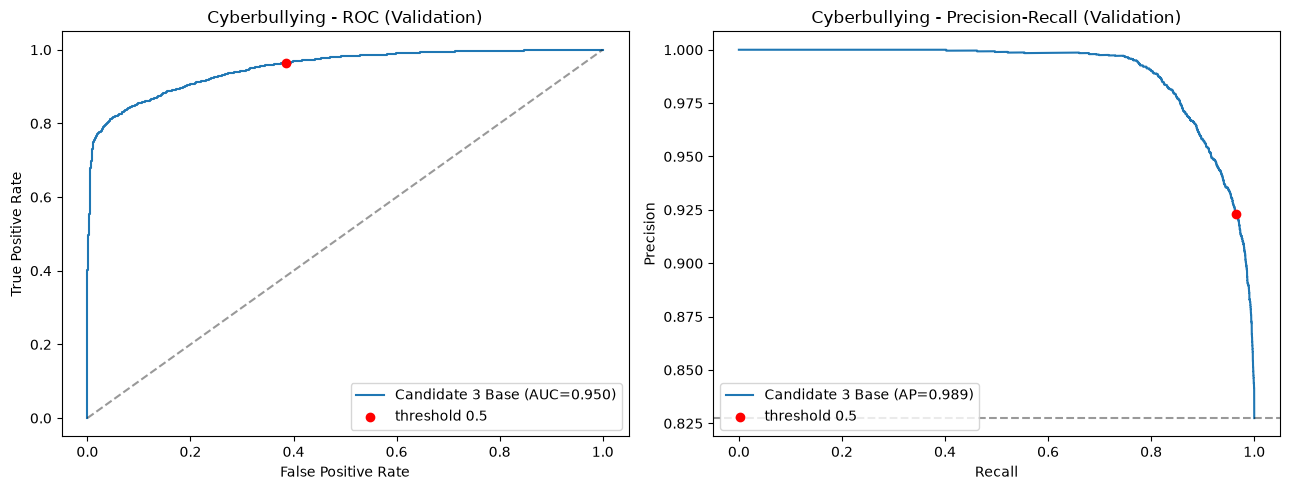

In [19]:
from sklearn.metrics import roc_curve, precision_recall_curve, average_precision_score

fpr, tpr, roc_thr = roc_curve(y_val, cyber_cnd_base_score)
prec, rec, pr_thr = precision_recall_curve(y_val, cyber_cnd_base_score)

# Where the default 0.5 threshold sits on the curves
pred_05 = cyber_cnd_base_score >= 0.5
fpr_05 = (pred_05 & (y_val == 0)).sum() / (y_val == 0).sum()
tpr_05 = (pred_05 & (y_val == 1)).sum() / (y_val == 1).sum()
prec_05 = (pred_05 & (y_val == 1)).sum() / max(pred_05.sum(), 1)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))

ax1.plot(fpr, tpr, label=f"Candidate 3 Base (AUC={roc_auc_score(y_val, cyber_cnd_base_score):.3f})")
ax1.plot([0, 1], [0, 1], "k--", alpha=0.4)
ax1.scatter([fpr_05], [tpr_05], color="red", zorder=3, label="threshold 0.5")
ax1.set(xlabel="False Positive Rate", ylabel="True Positive Rate", title="Cyberbullying - ROC (Validation)")
ax1.legend(loc="lower right")

ax2.plot(rec, prec, label=f"Candidate 3 Base (AP={average_precision_score(y_val, cyber_cnd_base_score):.3f})")
ax2.axhline(y_val.mean(), color="k", ls="--", alpha=0.4)
ax2.scatter([tpr_05], [prec_05], color="red", zorder=3, label="threshold 0.5")
ax2.set(xlabel="Recall", ylabel="Precision", title="Cyberbullying - Precision-Recall (Validation)")
ax2.legend(loc="lower left")

plt.tight_layout()
plt.show()

## Threshold Selection (Validation)

In [53]:
def threshold_at_fpr(y_true, probs, max_fpr):
    # Highest recall while the false positive rate stays at or below max_fpr
    fpr, tpr, thr = roc_curve(y_true, probs)
    i = np.where(fpr <= max_fpr)[0][-1]
    return thr[i]


def threshold_summary(y_true, probs, thresholds):
    rows = []
    for name, t in thresholds.items():
        pred = probs >= t
        precision = (pred & (y_true == 1)).sum() / max(pred.sum(), 1)
        recall = (pred & (y_true == 1)).sum() / (y_true == 1).sum()
        rows.append({
            "rule": name,
            "threshold": t,
            "recall (TPR)": recall,
            "false positive rate": (pred & (y_true == 0)).sum() / (y_true == 0).sum(),
            "precision": precision,
            "f1": 2 * precision * recall / max(precision + recall, 1e-12),
            "flagged %": pred.mean() * 100
        })
    return pd.DataFrame(rows)


# Best-F1 point from the precision-recall curve
f1_curve = 2 * prec[:-1] * rec[:-1] / np.maximum(prec[:-1] + rec[:-1], 1e-12)

candidate_thresholds = {
    "default 0.5": 0.5,
    "max recall, FPR <= 1%": threshold_at_fpr(y_val, cyber_cnd_base_score, 0.01),
    "max recall, FPR <= 3%": threshold_at_fpr(y_val, cyber_cnd_base_score, 0.03),
    "max recall, FPR <= 5%": threshold_at_fpr(y_val, cyber_cnd_base_score, 0.05),
    "max recall, FPR <= 6%": threshold_at_fpr(y_val, cyber_cnd_base_score, 0.06),
    "max recall, FPR <= 7%": threshold_at_fpr(y_val, cyber_cnd_base_score, 0.07),
    "max recall, FPR <= 10%": threshold_at_fpr(y_val, cyber_cnd_base_score, 0.10),
    "best F1": pr_thr[np.argmax(f1_curve)]
}

display(threshold_summary(y_val, cyber_cnd_base_score, candidate_thresholds))

# Pick the rule that fits the product, then use that value below
cyber_threshold = candidate_thresholds["max recall, FPR <= 6%"]
print("Chosen cyberbullying threshold:", cyber_threshold)

,rule,threshold,recall (TPR),false positive rate,precision,f1,flagged %
0,default 0.5,0.500000,0.964811,0.386230,0.922961,0.943422,86.498624
1,"max recall, FPR <= 1%",0.952462,0.730392,0.009236,0.997370,0.843254,60.596842
2,"max recall, FPR <= 3%",0.901957,0.784839,0.029387,0.992253,0.876442,65.449804
3,"max recall, FPR <= 5%",0.859746,0.814776,0.049538,0.987481,0.892854,68.274663
4,"max recall, FPR <= 6%",0.848728,0.821604,0.058774,0.985303,0.896038,68.998986
5,"max recall, FPR <= 7%",0.833196,0.831232,0.068850,0.983023,0.900778,69.969578
6,"max recall, FPR <= 10%",0.788622,0.855567,0.099916,0.976229,0.911924,72.519195
7,best F1,0.478571,0.969188,0.399664,0.920825,0.944388,87.092568


Chosen cyberbullying threshold: 0.8487283930774289


## Candidate Ensemble Test Result at Chosen Threshold

In [54]:
display(
    threshold_summary(
        y_test,
        cyber_cnd_base_test_score,
        {"default 0.5": 0.5, "chosen (tuned on validation)": cyber_threshold}
    )
)

print("Test ROC-AUC (any cyberbullying):", roc_auc_score(y_test, cyber_cnd_base_test_score))

,rule,threshold,recall (TPR),false positive rate,precision,f1,flagged %
0,default 0.5,0.500000,0.960091,0.385714,0.922779,0.941065,86.107489
1,chosen (tuned on validation),0.848728,0.826886,0.053782,0.986633,0.899724,69.361147


Test ROC-AUC (any cyberbullying): 0.9511337109673206
